## Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from hgctsvg.metadata import ProjectMetadata
from hgctsvg.preprocessing import common, singlecell, kidneycancer
from hgctsvg.utils import load_ct_spatial_data

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Identify source and results directories

In [2]:
results_dir = Path("hgctsvg_project_files")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(spotiphy_proj_dir / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(spotiphy_proj_dir / "Human Kidney Cancer Interface.h5ad")

The generated cell decomposition data does not yet include the cell locations generated by Spotiphy.
For visualization using Squidpy, we update adata with the generated locations.

In [5]:
adata_decomp = common.add_generated_cell_locations(spotiphy_proj_dir, adata_decomp, adata_st)

Prepared hires segmentation: (1834, 2000), 22430 cells


In [6]:
common_genes = set(adata_st.var_names).intersection(set(adata_decomp.var_names))
len(common_genes)

10827

### Make Project Metadata File

Generate a `ProjectMetadata` object. The `ProjectMetadata` file contains metadata about the project, which is used in several parts of the pipeline:
- `project_folder` - directory of the project.
- `ct_key` - cell type key used by adata objects to indicate the cell type of each cell.
- `ct_list` - list of cell types sorted in lexicographical order.
- `ct_mapping` - mapping of cell type names (`str`) to their positions in the `ct_list` (`int`). `ct_mapping` is important when preparing and accessing data in the pipeline.
- `n_cell_types` - number of cell types in the data.
- `dir_map` - mapping of directories to project subfolders

Creating `ProjectMetadata` requires `ct_key` as an argument, but once created, `ct_key` can also be accessed from the `ProjectMetadata`.

In [7]:
project_metadata = ProjectMetadata.create(project_files_dir, 
                             adata_decomp,
                             'cell_type')
# ct_metadata.ct_key, ct_metadata.ct_list, ct_metadata.ct_mapping, ct_metadata.n_cell_types

In [8]:
project_metadata.dir_map

{'attr_dir': 'attribution',
 'classifier_dir': 'classifiers',
 'clustering_dir': 'clustering',
 'ct_data_dir': 'ct_spatial_data',
 'plot_dir': 'plots'}

## Preprocessing

Preprocess original and decomposed ST data.

### General Preprocessing
Preprocess original ST data using standard preprocessing steps. Also perform HVG selection.

In [9]:
# Preprocessing and HVG detection
n_top_genes = 3000

# filter first before preprocess
adata_decomp = common.filter(adata_decomp, min_genes=20, min_locs=20)
adata_st = common.filter(adata_st, min_genes=20, min_locs=20)

# Preprocess ST data.
# Store unprocessed data to raw.
# Raw data is needed for visualization.
adata_st.raw = adata_st.copy()
sc.pp.highly_variable_genes(adata_st, flavor='seurat_v3', n_top_genes=n_top_genes)
sc.pp.normalize_total(adata_st, target_sum=1e6)
sc.pp.log1p(adata_st)

### Create separate anndata objects for each cell type.

For the decomposed data, we first separate them into different anndata objects per cell type using `preprocessing.singlecell.make_ct_spatial_data`, which also performs preprocessing on each anndata object separately. 

Then, get the top genes per cell type using `preprocessing.singlecell.perform_ct_feature_selection`.

In [10]:
n_features=3000
singlecell.make_ct_spatial_adata(adata_decomp)
singlecell.perform_ct_feature_selection(n_features=n_features)

Visualize the resulting anndata objects.

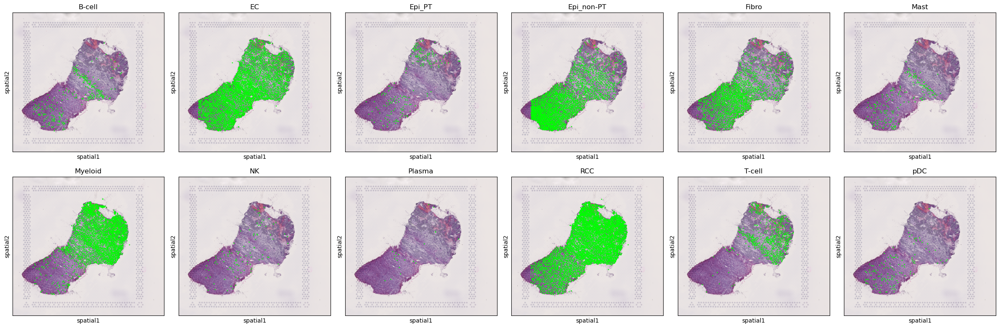

In [11]:
from hgctsvg.visualization import plot_all_ct_decomposition, plot_ct_decomposition
plot_all_ct_decomposition(n_cols=6)

# use this to plot each cell type separately
# plot_ct_decomposition(display=False, show_title=False)

Also visualize the distribution of genes on the original ST anndata object.

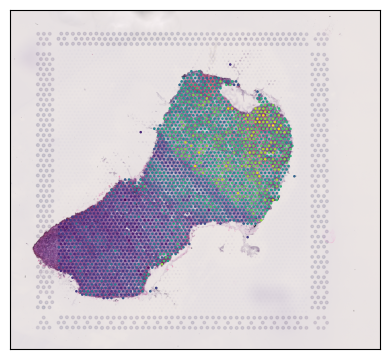

In [12]:
from hgctsvg.visualization import plot_st_gene_counts

plot_st_gene_counts(show_title=False, display=True)

## ML Dataset Creation

Create the Hypergraph Data for the ML pipeline.

In [13]:
hgdata = kidneycancer.create_hypergraph_data(adata_st, n_features=n_features, num_neighbor_spots=7)
hgdata.save()

Also save preprocessed ```adata_decomp``` and ```adata_st```

In [14]:
# save adata_st
adata_st.write_h5ad(project_files_dir / "ST_init.h5ad")

# save adata_decomp
adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

# HGCTSVG Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" 
```

## IV. Cell-type Specific Domain Identification

```bash
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cpu
```

## VI. Spatial Metagene Computation

### A. Compute Metagene Attribution to a Cell Type Spatial Domain
```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cuda
```

```bash
# Using CPU
hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cpu
```

### B. Compute Gene Attribution to Metagene

```bash
CUDA_VISIBLE_DEVICES=0 hgctsvg train-embedder --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg make-embedding --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
# hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface"
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" --data.cell-type-key "cell_type" --clustering.resolution 1
CUDA_VISIBLE_DEVICES=0 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-metagene-to-region-attribution --project "Human Kidney Cancer Interface" --cell-type EC --region 0 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-cell-metagene-attribution --project "Human Kidney Cancer Interface" --model.model-name SpatialFusionEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

```

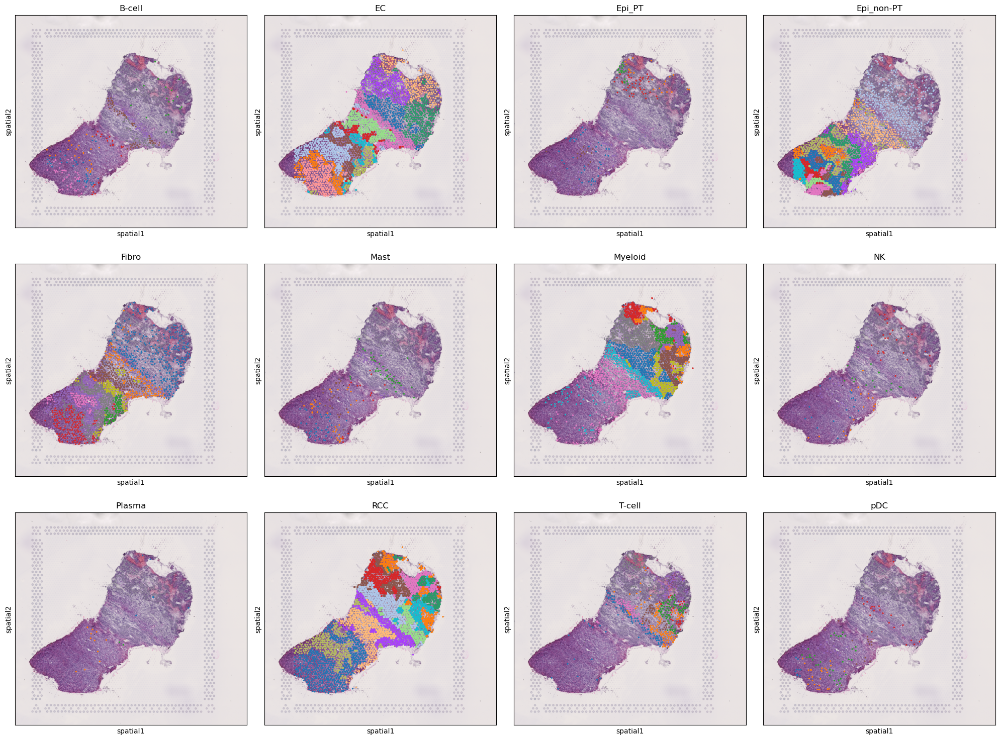

In [92]:
from hgctsvg.visualization import plot_all_ct_domains

plot_all_ct_domains()

In [93]:
adata_RCC = load_ct_spatial_data("RCC")
adata_RCC

AnnData object with n_obs × n_vars = 7176 × 10672
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'hvg_scores', 'spatial_scores', 'combined_scores', 'feature_gene'
    uns: 'cell_count', 'hvg', 'leiden', 'log1p', 'moranI', 'neighbors', 'sample_colors', 'spatial', 'spatial_neighbors'
    obsm: 'cell_nucleus', 'embedding', 'spatial'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

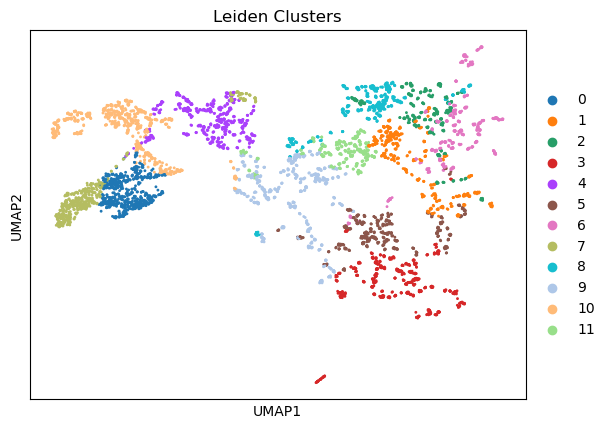

In [94]:
from scipy import sparse

sc.pp.neighbors(adata_RCC, use_rep='embedding', knn=False, method='gauss', key_added='umap')
adata_RCC.obsp['connectivities'] = sparse.csr_matrix(adata_RCC.obsp['connectivities'])
sc.tl.umap(adata_RCC)
sc.pl.umap(adata_RCC, color='leiden', title='Leiden Clusters')

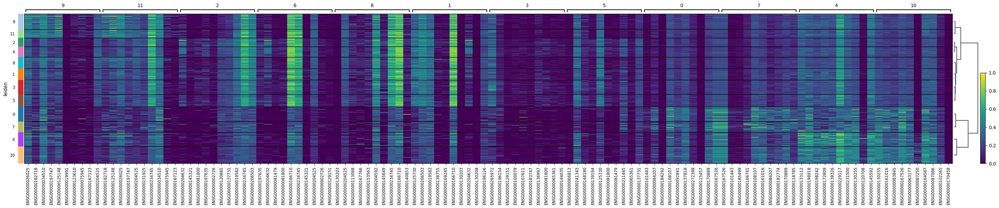

In [96]:
sc.tl.dendrogram(adata_RCC, var_names=adata_RCC.var_names[adata_RCC.var['feature_gene']], groupby='leiden')
sc.pl.rank_genes_groups_heatmap(
    adata_RCC,
    n_genes=10,
    standard_scale="var",
    show_gene_labels=True,
)

In [369]:
def compute_spatial_de_genes(project: Path,
                             cell_type: str,
                             key: str = 'leiden',
                             percentile: int = 0,
                             min_pts: float = 0.8,
                             min_precision: float = 0.1,
                             rank_by: str = 'pvals_adj',
                             use_raw = False
                            ):

    project_metadata = ProjectMetadata()
    
    # load adata for cell type
    adata_ct = load_ct_spatial_data(cell_type)
    
    sc.tl.rank_genes_groups(adata_ct, 
                            groupby=key,
                            method="wilcoxon",
                            pts=True,
                            use_raw=use_raw)
    
    rg = adata_ct.uns['rank_genes_groups']
    groups = list(rg['names'].dtype.names)

    results = {}

    for group in groups:
        df = sc.get.rank_genes_groups_df(
            adata_ct, group=group,
        )

        # group_idx = groups.index(group)

        df['pts'] = df['names'].map(rg['pts'][group])
        df['pts_rest'] = df['names'].map(rg['pts_rest'][group])
        
        # n_c = (adata_ct.obs[key] == group).sum()
        # n_r = (adata_ct.obs[key] != group).sum()

        # df['recall'] = df['pts']
        # df['precision'] = (
        #     df["pts"] * n_c /
        #     (df["pts"] * n_c + df["pts_rest"] * n_r + 1e-12)
        # )
        
        # df['specificity'] = df['pts'] - df['pts_rest']
        # df['f1'] = (
        #     2 * df['precision'] * df['recall'] / (df['precision'] + df['recall'] + 1e-12)
        # )

        # Filter irrelevant genes, downregulated genes, low coverage genes
        df = df[
            (df['pvals_adj'] < 0.05) &
            # only select genes expressed in at least 80% of the region
            (df['pts'] > 0.8) &
            # select genes expressed more in the region than outside
            ((df['pts'] / df['pts_rest']) > 1) &
            # only select genes that are upregulated
            (df['logfoldchanges'] > 1.5)
        ]

        # df["consistency_rank"] = df["scores"].rank(pct=True)
        # df["f1_rank"] = df["f1"].rank(pct=True)
        # df["precision_rank"] = df["precision"].rank(pct=True)
        
        # df["consistency+f1"] = (
        #     df["consistency_rank"] + 
        #     df["f1_rank"]
        # ) / 2

        # df["consistency+precision"] = (
        #     df["consistency_rank"] + 
        #     df["precision_rank"]
        # ) / 2

        threshold = df[rank_by].abs().quantile(percentile)
        top_df = df[df[rank_by].abs() >= threshold]
        results[group] = top_df.sort_values(rank_by)
    
        # df = df.sort_values("combined_score", ascending=False)

        # top_df = df.nsmallest(n_results, "combined_score")
        # results[group] = top_df
        
    return results

def merge_spatial_de_genes(spatial_de_genes_group, 
                           rank_by: str = 'scores'):
    all_genes = {}
    for group in spatial_de_genes_group.keys():
        genes_group = spatial_de_genes_group[group]
        for i in range(len(genes_group)):
            name = genes_group.iloc[i]['names']
            score = genes_group.iloc[i][rank_by]
            if name not in all_genes:
                all_genes[name] = (score, group)
            else:
                current_score, _ = all_genes[name]
                if score > current_score:
                    all_genes[name] = (score, group)

    all_genes_df = pd.DataFrame.from_dict(
        all_genes,
        orient="index",
        columns = ['scores', 'region']
    ).sort_values(['region', 'scores'], ascending=[True, False])
    
    return all_genes_df

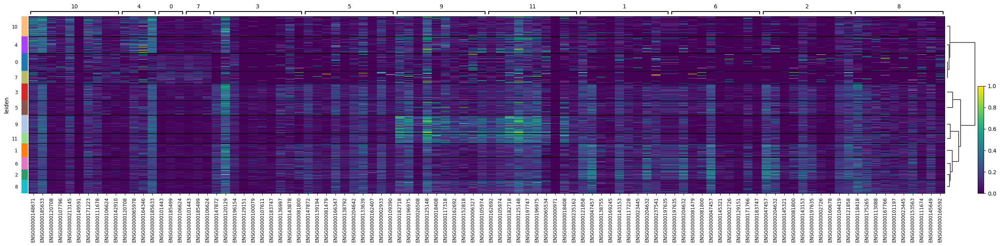

In [370]:
# from hgctsvg.pipeline import compute_spatial_de_genes, merge_spatial_de_genes
from hgctsvg.visualization import plot_ct_marker_groups_heatmap

top_genes_RCC = compute_spatial_de_genes(project_files_dir, "RCC", percentile = 0, rank_by='pvals_adj')
plot_ct_marker_groups_heatmap(adata_RCC, top_genes_RCC)

In [371]:
for group in top_genes_RCC:
    print(len(top_genes_RCC[group]))

# only ratio
# 49
# 910
# 1542
# 1155
# 133
# 962
# 1652
# 13
# 1745
# 1042
# 259
# 942

# 10
# 88
# 115
# 104
# 99
# 108
# 143
# 5
# 118
# 108
# 136
# 101

# only 80%
# 76
# 88
# 115
# 104
# 114
# 108
# 143
# 61
# 118
# 109
# 143
# 101

3
109
463
174
4
111
601
3
489
165
12
207


In [372]:
top_genes_RCC['3']

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference,pts,pts_rest
1,ENSG00000147872,24.196165,3.234649,2.441387e-129,1.302724e-125,1.000000,0.733641,1.000000,0.733641
2,ENSG00000120129,22.824116,1.768804,2.642258e-115,9.399394e-112,1.000000,0.874057,1.000000,0.874057
3,ENSG00000196154,22.296637,1.589801,3.983422e-110,1.062777e-106,1.000000,0.869592,1.000000,0.869592
4,ENSG00000129151,22.037699,4.382699,1.253491e-107,2.675450e-104,0.861968,0.341801,0.861968,0.341801
5,ENSG00000100079,22.017498,4.069861,1.957804e-107,3.482282e-104,0.867841,0.387683,0.867841,0.387683
...,...,...,...,...,...,...,...,...,...
1980,ENSG00000122565,4.537385,1.553469,5.695589e-06,2.833315e-05,0.935389,0.726867,0.935389,0.726867
2092,ENSG00000158089,4.380240,1.523811,1.185485e-05,5.580723e-05,0.842878,0.631563,0.842878,0.631563
2419,ENSG00000235162,3.960269,1.769721,7.486546e-05,3.051811e-04,0.901615,0.667436,0.901615,0.667436
2555,ENSG00000196141,3.779841,1.781731,1.569287e-04,6.061322e-04,0.933921,0.690223,0.933921,0.690223


In [373]:
top_genes_RCC_merged = merge_spatial_de_genes(top_genes_RCC)
len(top_genes_RCC_merged)

945

In [384]:
for g in sorted(top_genes_RCC_merged['region'].unique()):
    print(g, len(top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]))

0 2
1 23
10 11
11 73
2 155
3 83
4 2
5 18
6 289
7 1
8 190
9 98


In [382]:
top_genes_RCC_merged[top_genes_RCC_merged['region'] == '0']

,scores,region
ENSG00000101443,34.853668,0
ENSG00000106624,17.923382,0


In [375]:
def plot_top_domain_de_genes(adata, top_genes, regions = list[str], 
                             figsize=(4, 4), n_cols = 4, use_raw=False,
                             save=True, transparent=True, file_ext='png'):

    project_metadata = ProjectMetadata()
    
    n_rows = ((len(regions) // n_cols) + (1 if (len(regions) % n_cols) > 0 else 0)) * 2
    width, height = figsize
    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(width * n_cols, height * n_rows))
    
    for i in range((n_rows // 2 * n_cols)):
        row = (i // n_cols) * 2
        col = i % n_cols
        ax_region = axes[row][col]
        ax_expr = axes[row + 1][col]
        if i < len(regions):
            region = regions[i]
            adata_region = adata[adata.obs['leiden'] == str(region)]
            adata_plot = adata.copy()

            gene_id = top_genes[top_genes['region'] == region]['scores'].idxmax()
            gene_name = adata.var.loc[gene_id]['SYMBOL']
            score = top_genes.loc[gene_id]['scores']
            
            if use_raw:
                vals = adata_plot.raw[:,gene_id].X
            else:
                vals = adata_plot[:,gene_id].X
            # remove zeros
            nz = vals[vals > 0]
            vmin = np.percentile(nz, 5)
            vmax = np.percentile(nz, 95)
            
            sq.pl.spatial_scatter(
                adata_region,
                color='leiden',
                title=f"region {region}",
                ax=ax_region,
                legend_loc=None
            )
            sq.pl.spatial_scatter(
                adata_plot,
                color = gene_id,
                ax = ax_expr,
                title=f"{gene_name}: {score:0.4}",
                use_raw=use_raw,
                vmin=vmin,
                vmax=vmax,
                colorbar=False)
            ax_region.axis('off')
            ax_expr.axis('off')
        else:
            fig.delaxes(ax_region)
            fig.delaxes(ax_expr)

    plt.tight_layout()
    
    if save:
        plt.savefig(project_metadata.plot_dir / f'top_de_genes.{file_ext}', transparent=True)
    
    plt.show()


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

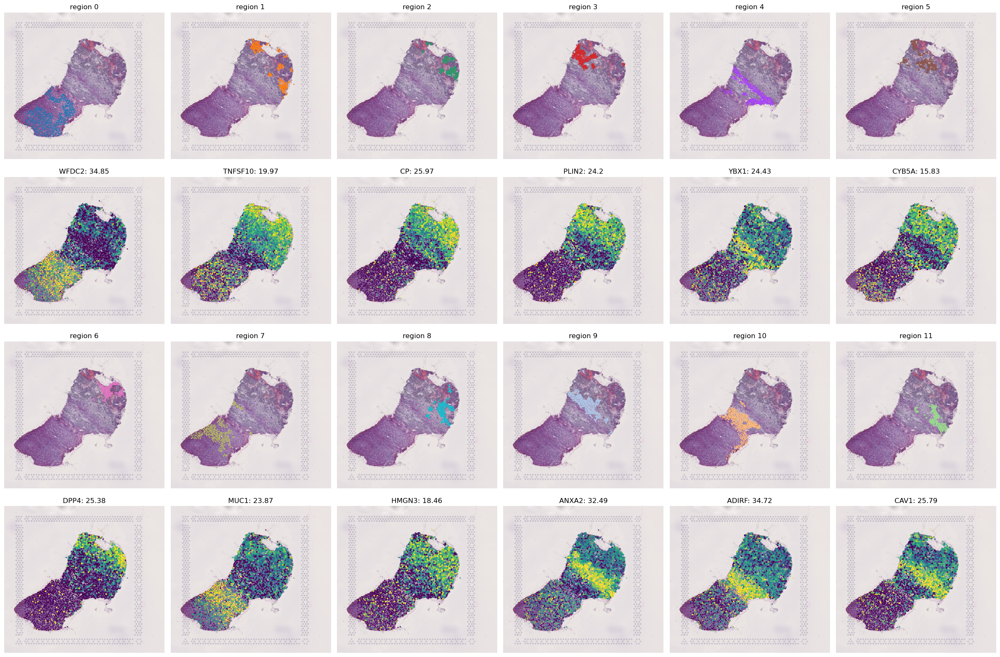

In [389]:
# from hgctsvg.visualization import plot_top_domain_de_genes

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_RCC_merged['region'].unique(), key=lambda r: int(r))
plot_top_domain_de_genes(adata_RCC, top_genes_RCC_merged, groups, n_cols=6, save=True)

In [377]:
1834 / 0.18601191, 2000 / 0.18601191

(9859.583722354122, 10751.999697223688)

## adata_RCC.uns["spatial"][library_id]

(7176, 1)
4.453886013465138 7.497750605316738


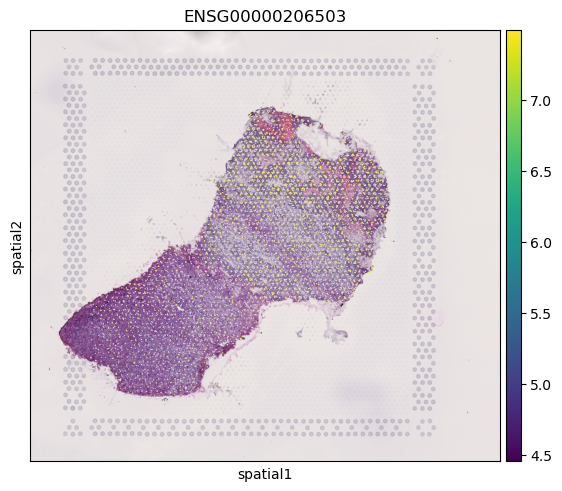

In [378]:
adata_RCC.uns["spatial"][library_id]["scalefactors"]["tissue_segmentation_scalef"] = 1
library_id = list(adata_RCC.uns["spatial"].keys())[0]

vals = adata_RCC[:,'ENSG00000101443'].X
print(vals.shape)
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)
print(vmin, vmax)
sq.pl.spatial_segment(
    adata_RCC,
    seg_cell_id="segmentation",
    color='ENSG00000206503',
    library_key='library_id',
    # figsize=(32,32),
    vmin=vmin,
    vmax=vmax,
    # crop_coord=[(1500,900,1800,1500)]
)

In [379]:
adata_RCC

AnnData object with n_obs × n_vars = 7176 × 10672
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'hvg_scores', 'spatial_scores', 'combined_scores', 'feature_gene'
    uns: 'cell_count', 'hvg', 'leiden', 'log1p', 'moranI', 'neighbors', 'sample_colors', 'spatial', 'spatial_neighbors', 'umap', 'leiden_colors', 'rank_genes_groups', 'dendrogram_leiden', 'pca'
    obsm: 'cell_nucleus', 'embedding', 'spatial', 'X_umap', 'X_pca'
    varm: 'PCs'
    obsp: 'connectivities', 'distances', 'spatial_connectivit

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


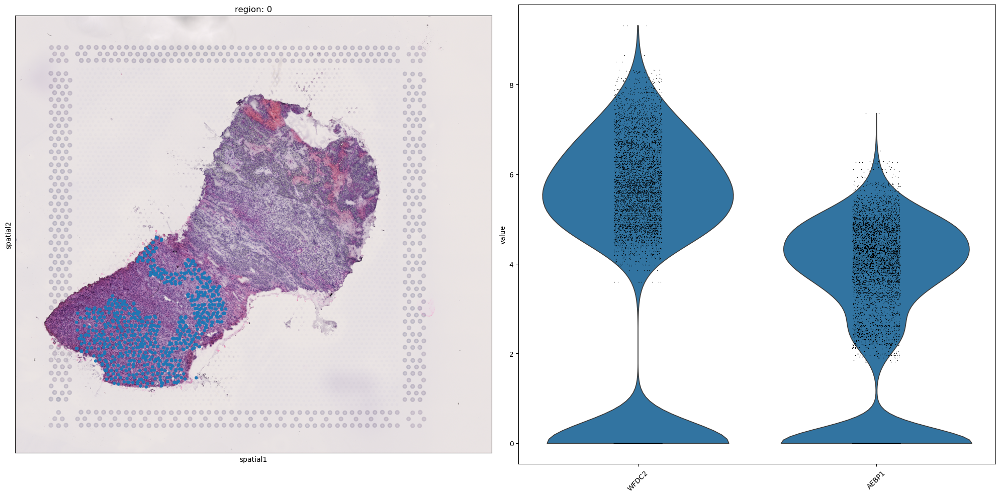

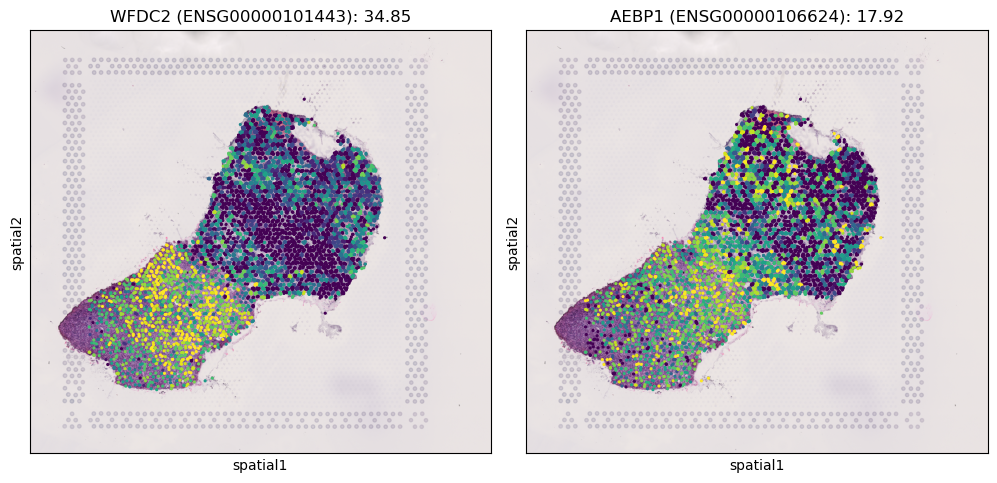

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


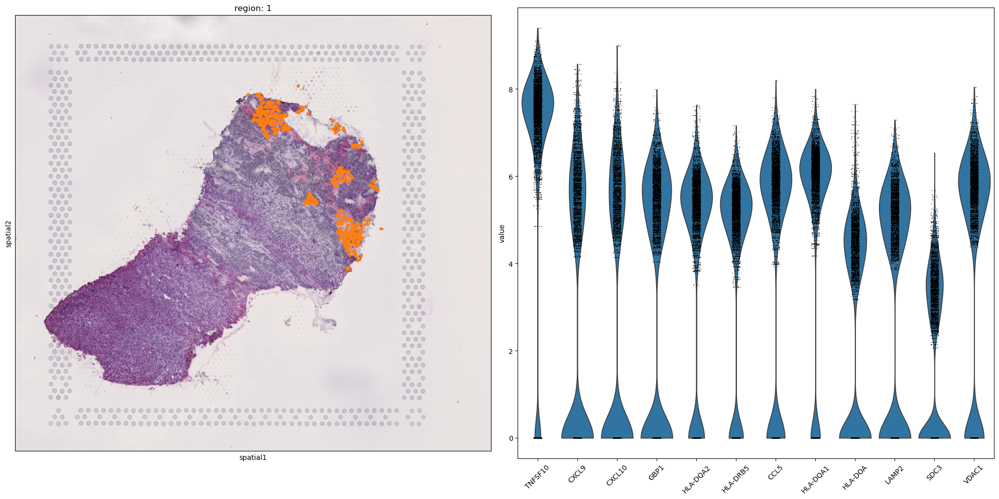

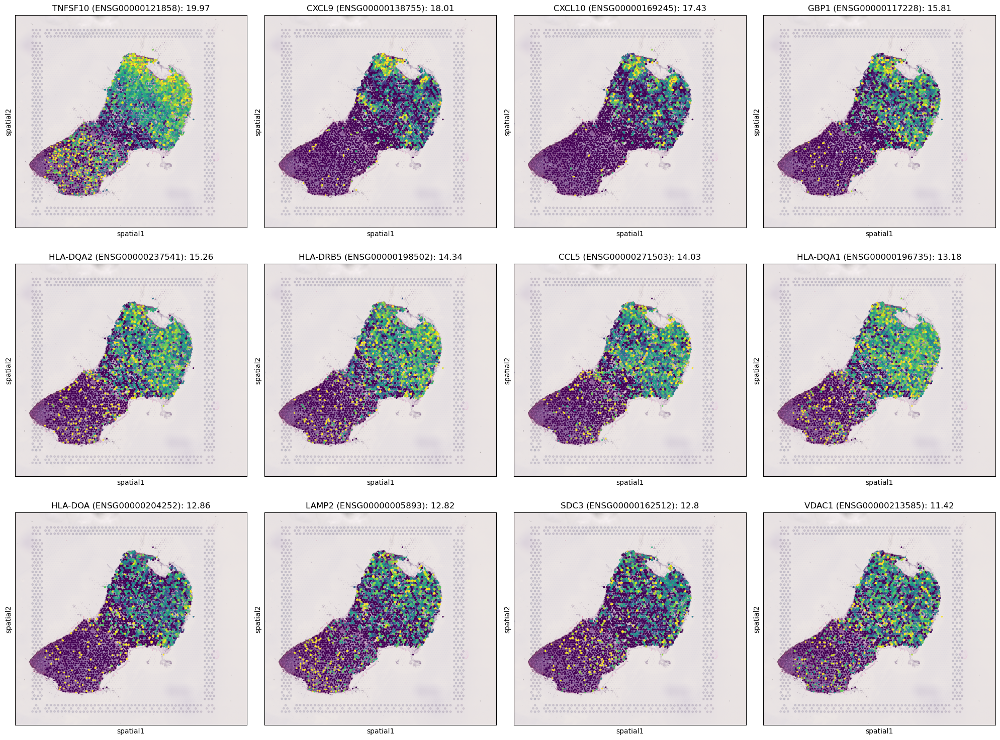

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


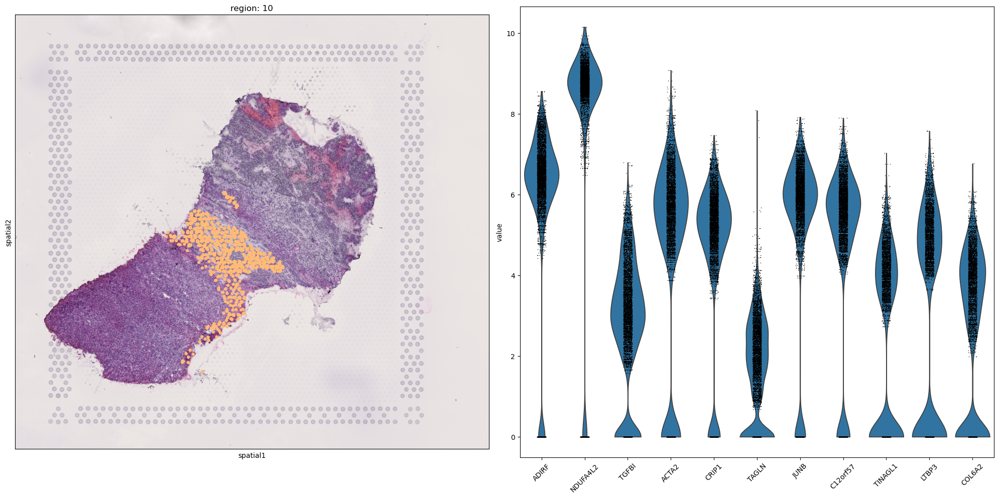

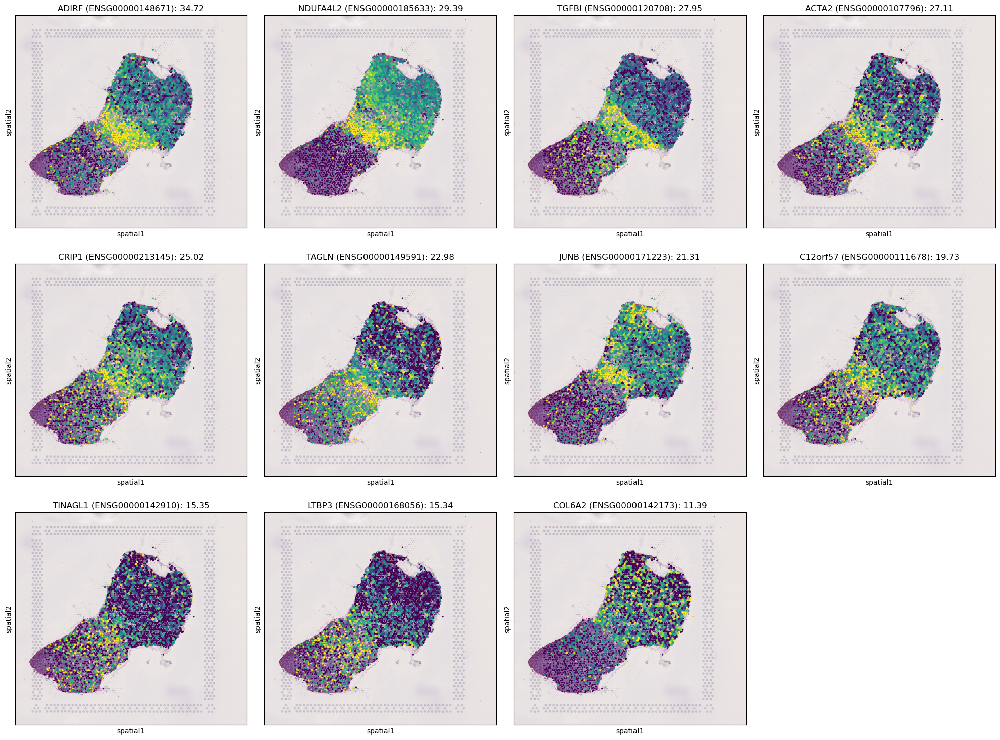

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


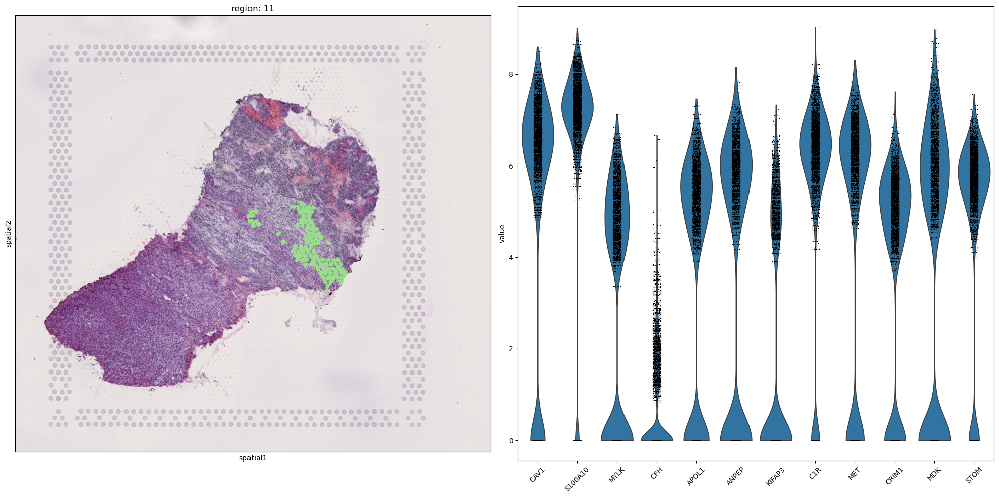

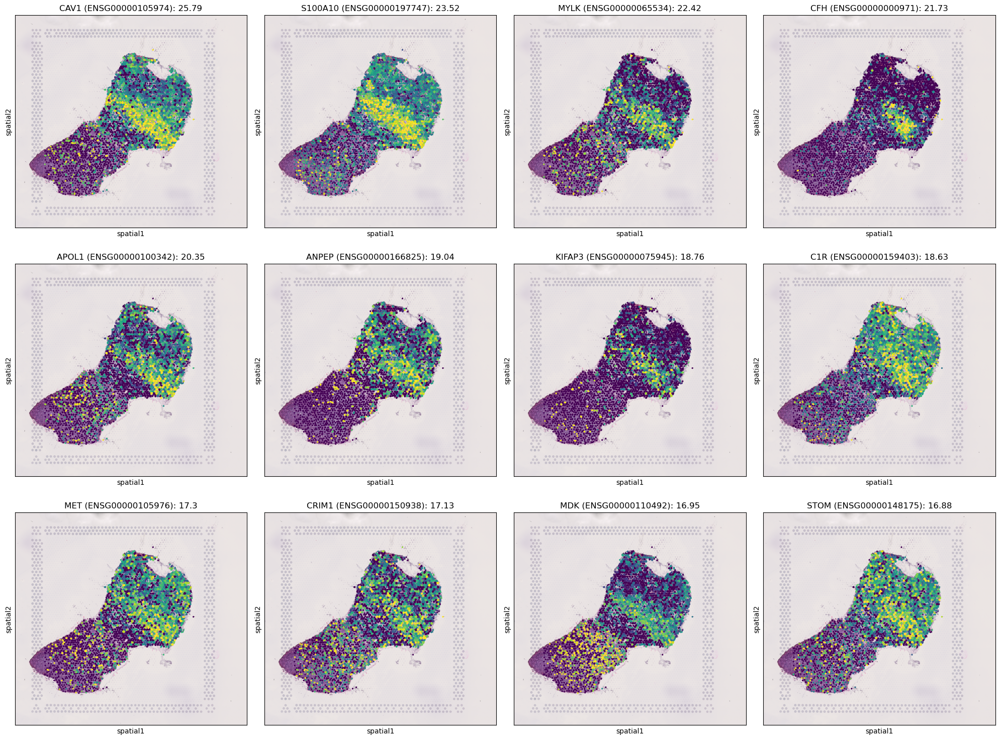

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


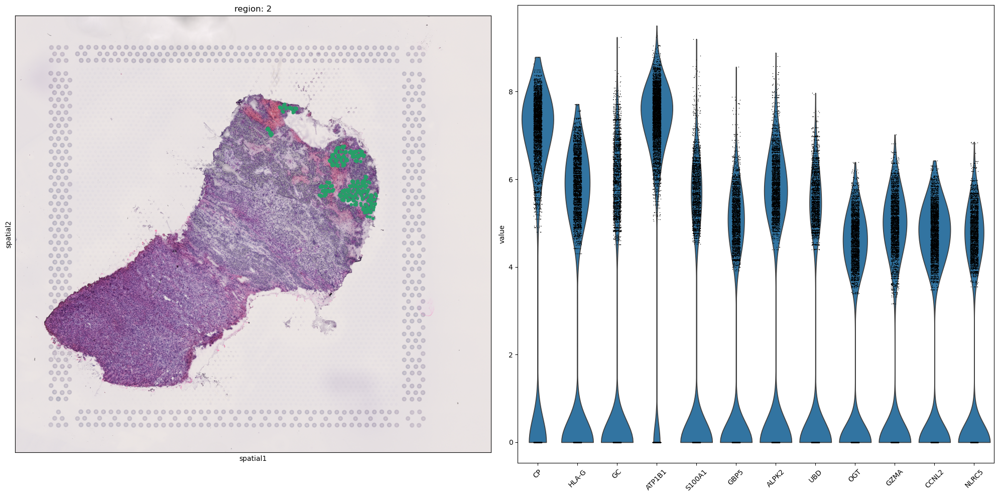

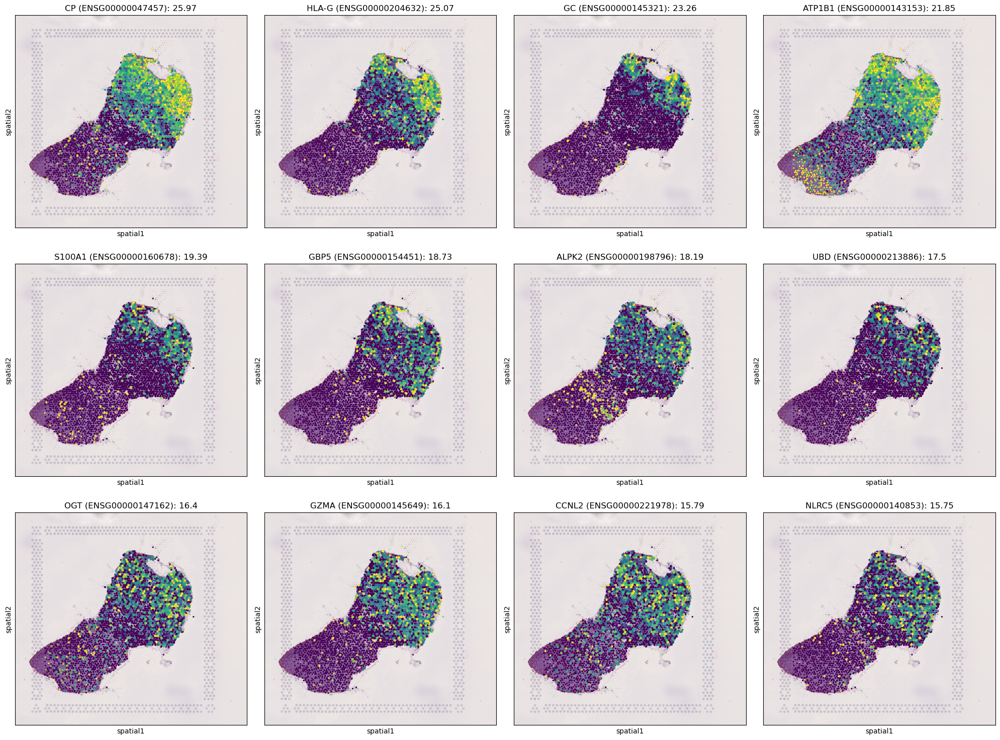

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


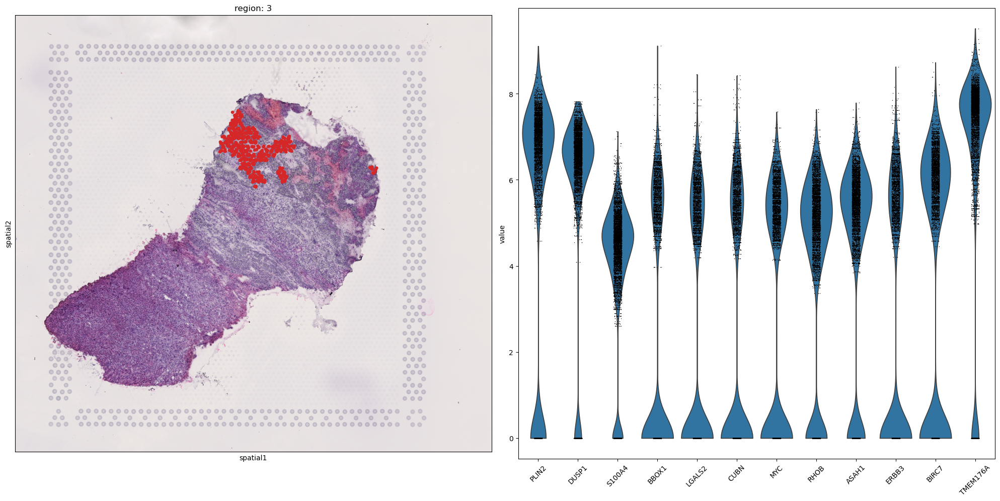

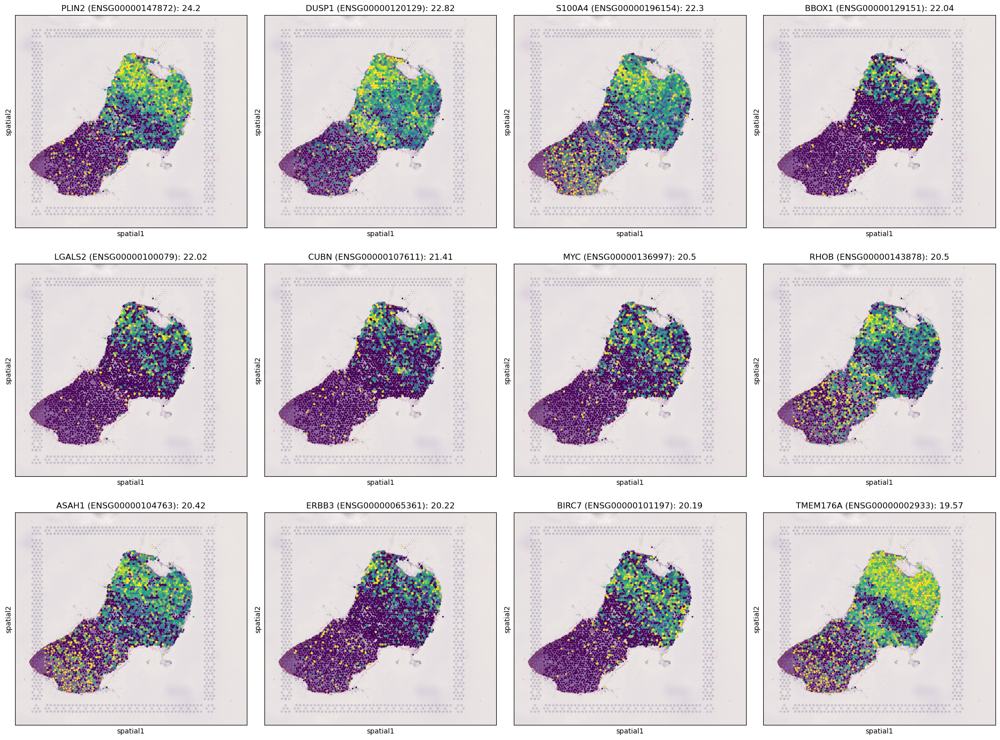

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


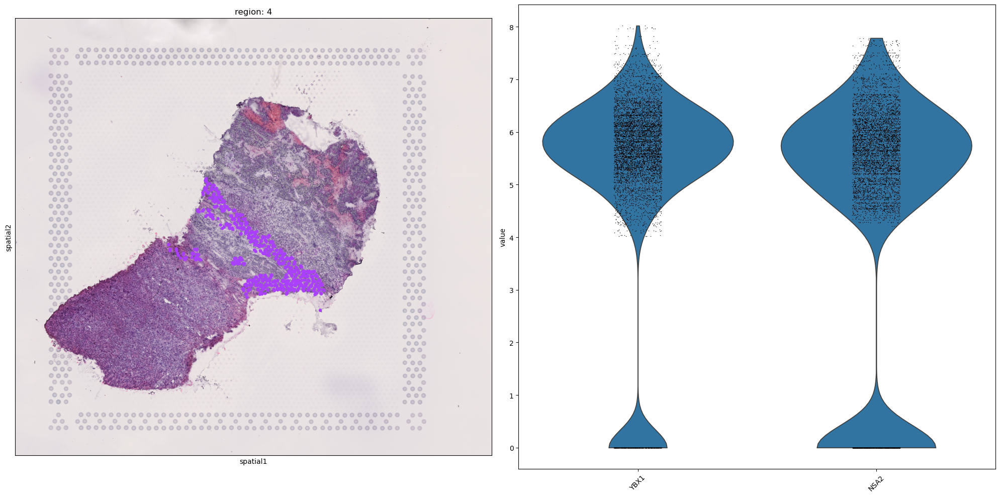

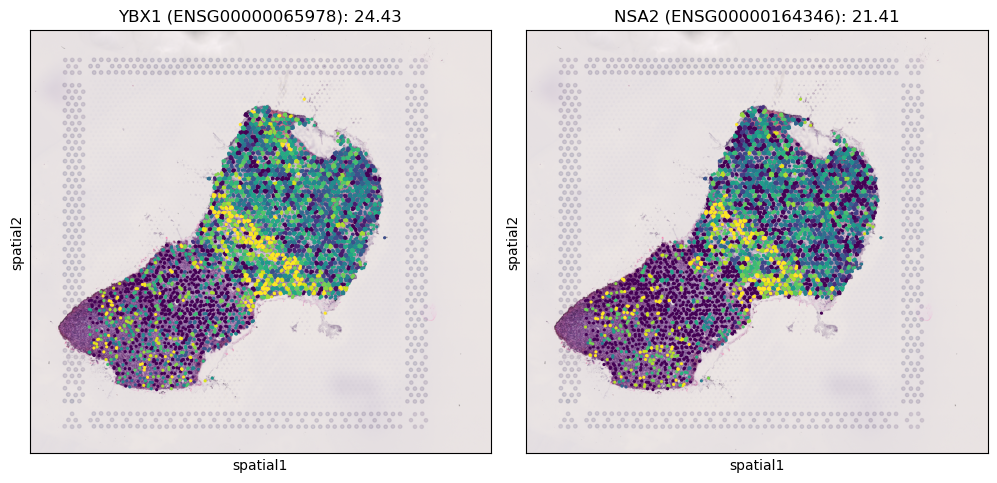

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


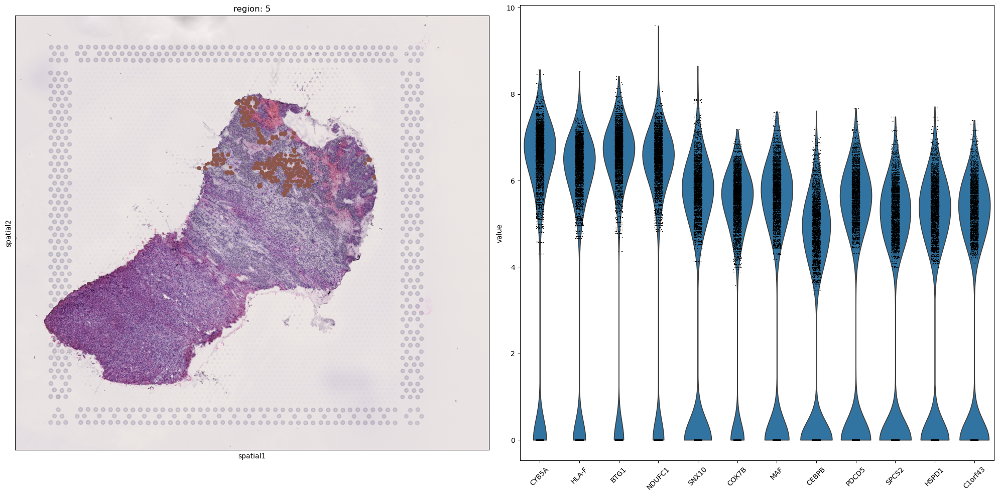

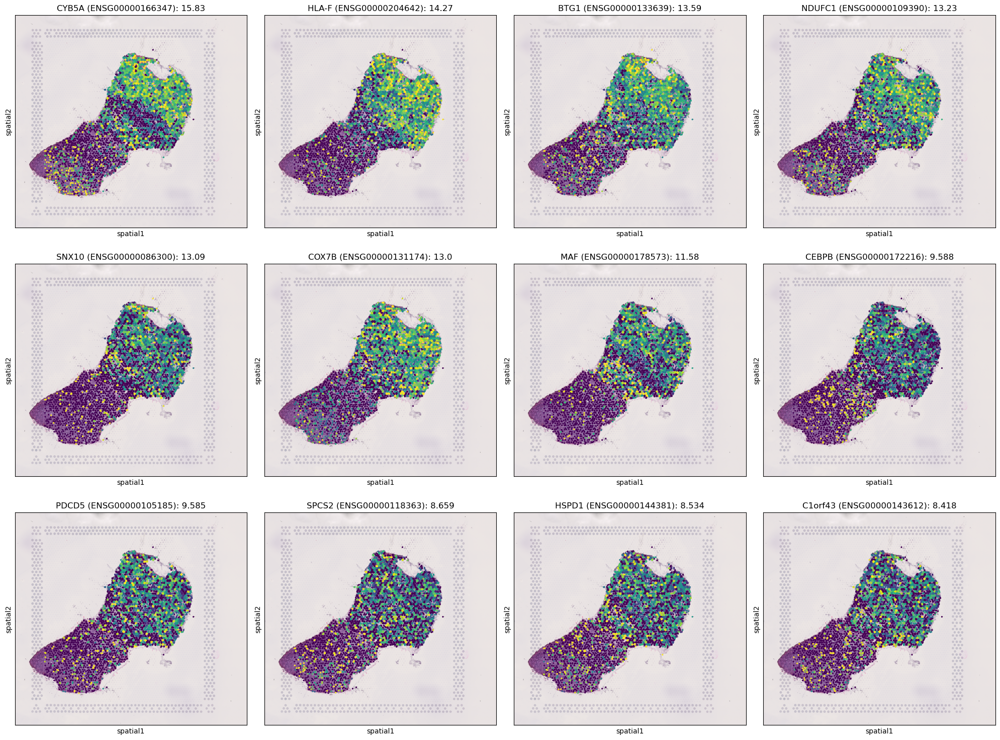

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


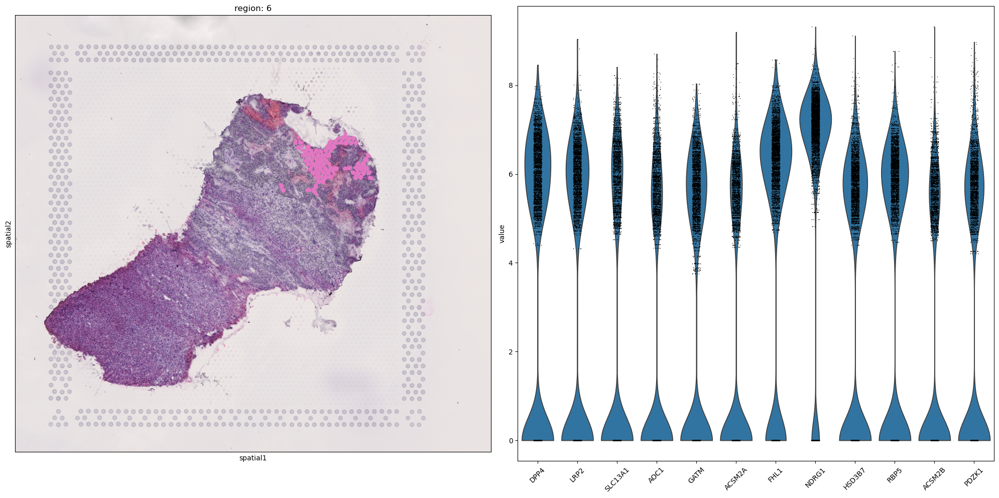

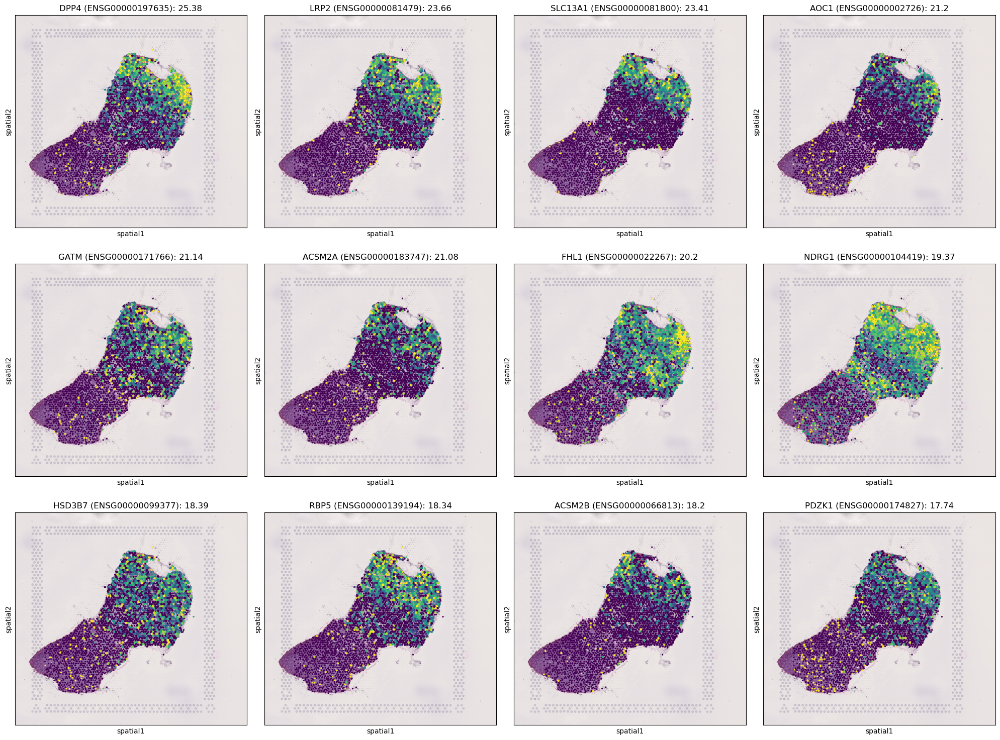

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


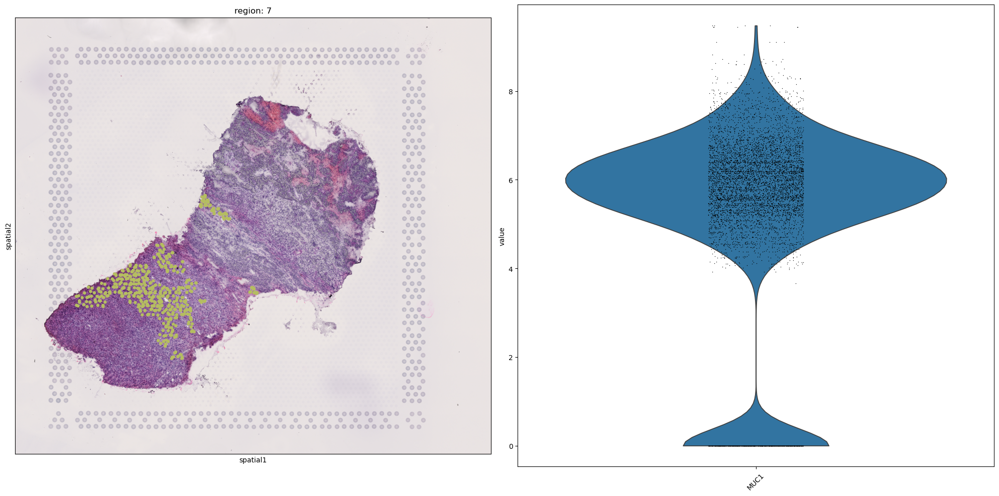

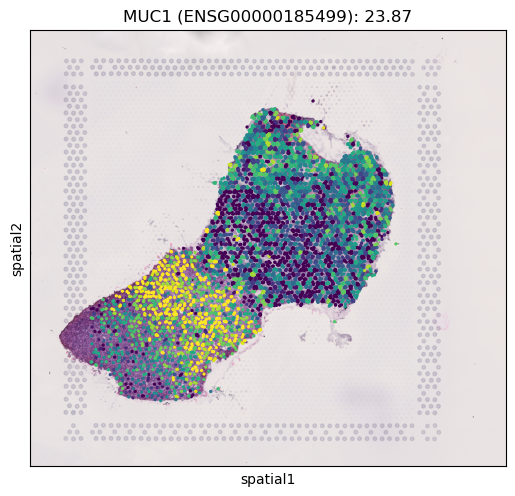

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


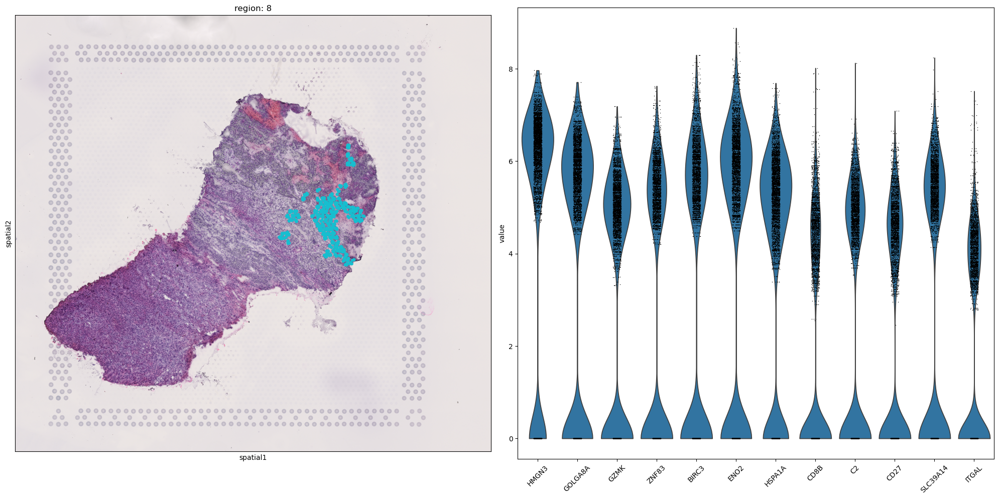

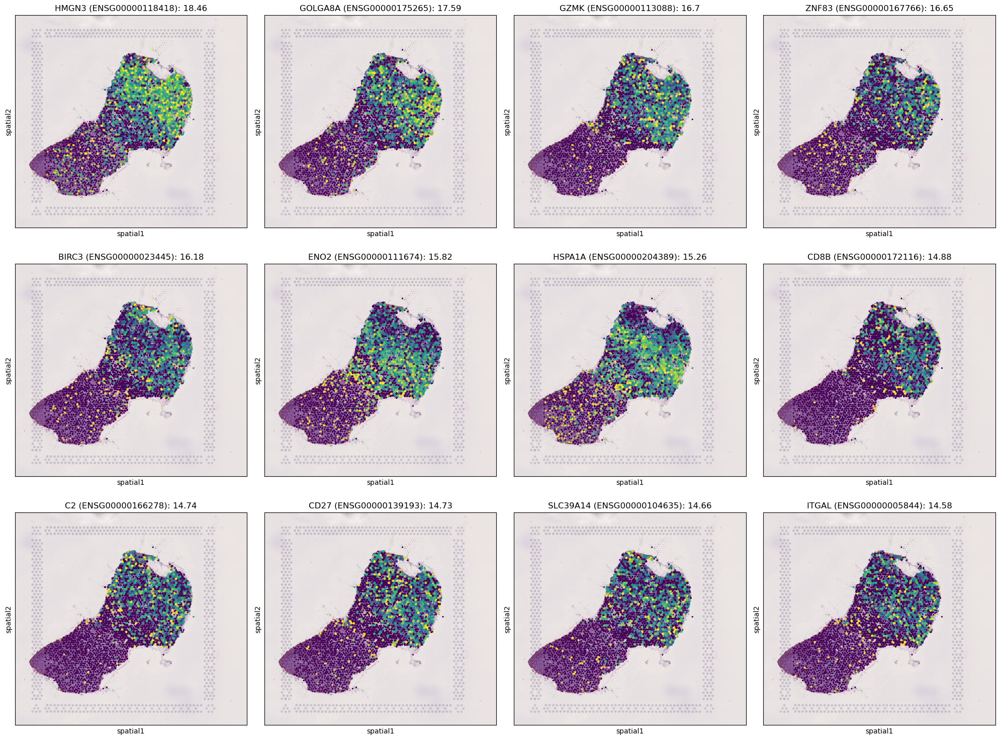

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


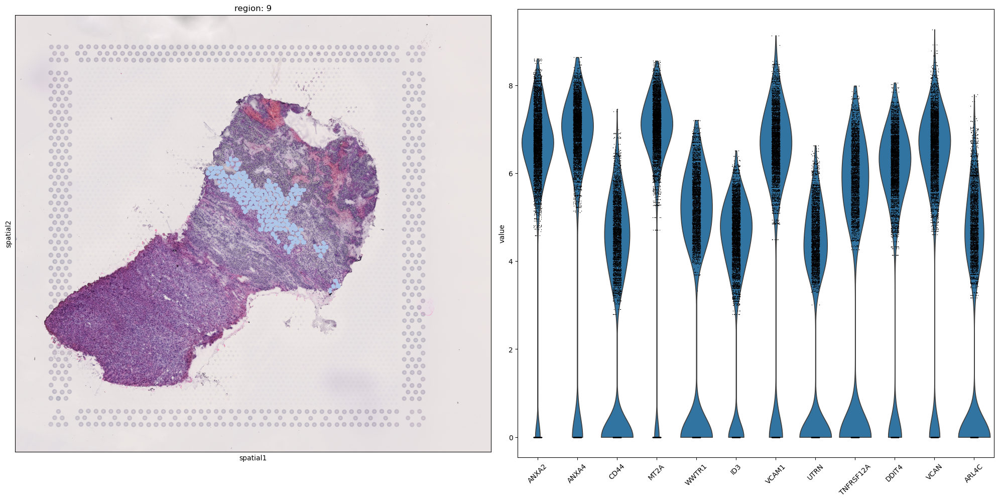

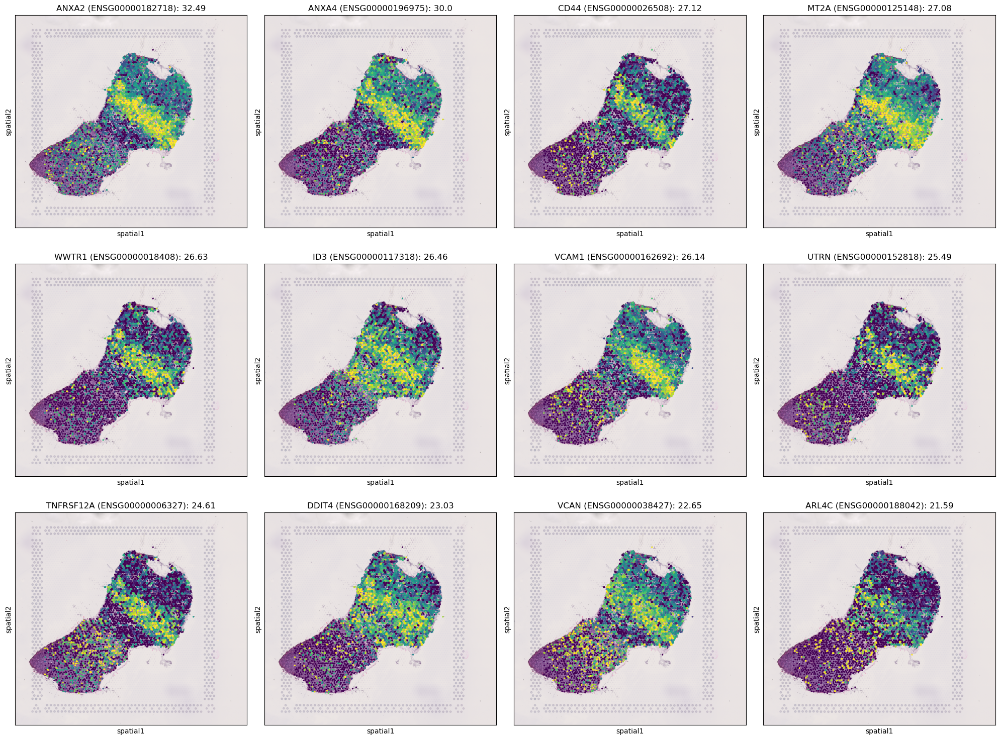

In [381]:
from hgctsvg.visualization import plot_domain_ct_svgs
groups = sorted(adata_RCC.obs['leiden'].unique())
for g in groups:
    top_genes_RCC_group = top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]
    top_genes_RCC_group = top_genes_RCC_group.sort_values('scores', ascending=False)
    scores = top_genes_RCC_group['scores'].tolist()
    indexes = top_genes_RCC_group.index.tolist()
    plot_domain_ct_svgs(adata_RCC, int(g), scores, indexes, use_raw=False)
    # plot_domain_de_genes(adata_RCC, int(g), top_genes[g]["scores"], top_genes[g]["indexes"])
    # plot_domain_de_genes(adata_RCC, int(g), list(top_genes_RCC[g]["scores"]), list(top_genes_RCC[g]["names"]))

In [ ]:
interest_genes = ['NDRG', 'RPL13', 'TMEM45A']

In [ ]:
adata_RCC.var[adata_RCC.var.index != 'RPL13']

In [ ]:
adata_RCC.var[adata_RCC.var['SYMBOL'] == 'NDRG1']

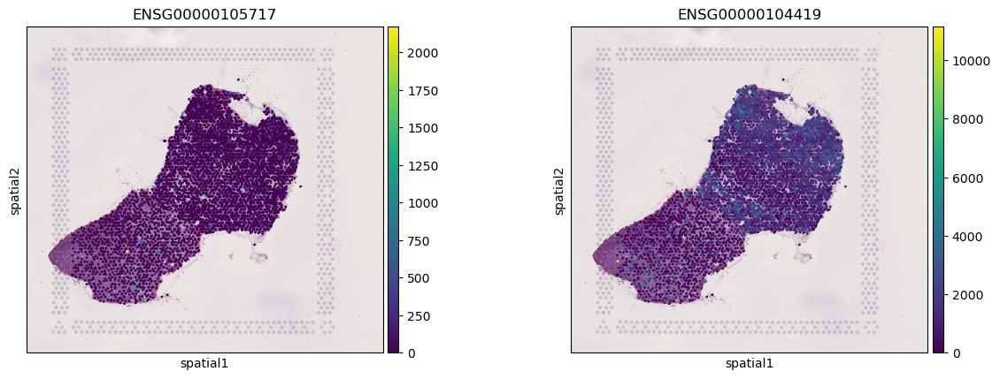

In [281]:
sq.pl.spatial_scatter(adata_RCC, color=['ENSG00000105717', 'ENSG00000104419'])

In [ ]:
adata_RCC

In [ ]:
adata_decomp.uns['spatial']['spaceranger130_count_44214_6800STDY12499411_GRCh38-2020-A']

In [ ]:
'leiden_colors' in adata_RCC_merged.uns

In [ ]:
adata_RCC_merged.uns

In [ ]:
adata_RCC_merged.uns.pop('leiden_colors')
sq.pl.spatial_scatter(adata_RCC_merged, color='leiden')